In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

df = pd.read_csv("House_Rent_Dataset.csv")

print("Dataset Loaded Successfully!")
print("Dataset Shape:", df.shape)
display(df.head())

Dataset Loaded Successfully!
Dataset Shape: (4746, 12)


,Posted On,BHK,Rent,Size,Floor,Area Type,Area Locality,City,Furnishing Status,Tenant Preferred,Bathroom,Point of Contact
0,2022-05-18,2,10000,1100,Ground out of 2,Super Area,Bandel,Kolkata,Unfurnished,Bachelors/Family,2,Contact Owner
1,2022-05-13,2,20000,800,1 out of 3,Super Area,"Phool Bagan, Kankurgachi",Kolkata,Semi-Furnished,Bachelors/Family,1,Contact Owner
2,2022-05-16,2,17000,1000,1 out of 3,Super Area,Salt Lake City Sector 2,Kolkata,Semi-Furnished,Bachelors/Family,1,Contact Owner
3,2022-07-04,2,10000,800,1 out of 2,Super Area,Dumdum Park,Kolkata,Unfurnished,Bachelors/Family,1,Contact Owner
4,2022-05-09,2,7500,850,1 out of 2,Carpet Area,South Dum Dum,Kolkata,Unfurnished,Bachelors,1,Contact Owner


In [3]:
print("Column Names:")
print(df.columns.tolist())

print("\nData Types:")
print(df.dtypes)

print("\nMissing Values:")
print(df.isnull().sum())

Column Names:
['Posted On', 'BHK', 'Rent', 'Size', 'Floor', 'Area Type', 'Area Locality', 'City', 'Furnishing Status', 'Tenant Preferred', 'Bathroom', 'Point of Contact']

Data Types:
Posted On              str
BHK                  int64
Rent                 int64
Size                 int64
Floor                  str
Area Type              str
Area Locality          str
City                   str
Furnishing Status      str
Tenant Preferred       str
Bathroom             int64
Point of Contact       str
dtype: object

Missing Values:
Posted On            0
BHK                  0
Rent                 0
Size                 0
Floor                0
Area Type            0
Area Locality        0
City                 0
Furnishing Status    0
Tenant Preferred     0
Bathroom             0
Point of Contact     0
dtype: int64


In [4]:
print("Duplicate Rows:", df.duplicated().sum())

df = df.drop_duplicates()
df = df.dropna(subset=["Rent"])

print("Dataset Shape After Cleaning:", df.shape)
print("\nMissing Values After Cleaning:")
print(df.isnull().sum())

Duplicate Rows: 0
Dataset Shape After Cleaning: (4746, 12)

Missing Values After Cleaning:
Posted On            0
BHK                  0
Rent                 0
Size                 0
Floor                0
Area Type            0
Area Locality        0
City                 0
Furnishing Status    0
Tenant Preferred     0
Bathroom             0
Point of Contact     0
dtype: int64


In [5]:
print("Rent Statistics:")
print(df["Rent"].describe())

print("\nCity-wise House Count:")
print(df["City"].value_counts())

display(df.head())

Rent Statistics:
count    4.746000e+03
mean     3.499345e+04
std      7.810641e+04
min      1.200000e+03
25%      1.000000e+04
50%      1.600000e+04
75%      3.300000e+04
max      3.500000e+06
Name: Rent, dtype: float64

City-wise House Count:
City
Mumbai       972
Chennai      891
Bangalore    886
Hyderabad    868
Delhi        605
Kolkata      524
Name: count, dtype: int64


,Posted On,BHK,Rent,Size,Floor,Area Type,Area Locality,City,Furnishing Status,Tenant Preferred,Bathroom,Point of Contact
0,2022-05-18,2,10000,1100,Ground out of 2,Super Area,Bandel,Kolkata,Unfurnished,Bachelors/Family,2,Contact Owner
1,2022-05-13,2,20000,800,1 out of 3,Super Area,"Phool Bagan, Kankurgachi",Kolkata,Semi-Furnished,Bachelors/Family,1,Contact Owner
2,2022-05-16,2,17000,1000,1 out of 3,Super Area,Salt Lake City Sector 2,Kolkata,Semi-Furnished,Bachelors/Family,1,Contact Owner
3,2022-07-04,2,10000,800,1 out of 2,Super Area,Dumdum Park,Kolkata,Unfurnished,Bachelors/Family,1,Contact Owner
4,2022-05-09,2,7500,850,1 out of 2,Carpet Area,South Dum Dum,Kolkata,Unfurnished,Bachelors,1,Contact Owner


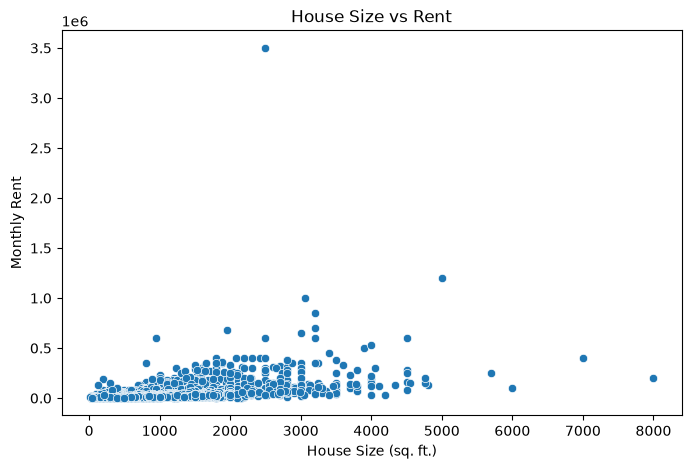

In [6]:
plt.figure(figsize=(8, 5))

sns.scatterplot(data=df, x="Size", y="Rent")

plt.title("House Size vs Rent")
plt.xlabel("House Size (sq. ft.)")
plt.ylabel("Monthly Rent")
plt.show()

In [7]:
X = df[["BHK", "Size", "Bathroom"]]
y = df["Rent"]

print("Input Features:")
display(X.head())

print("Target Rent:")
print(y.head())

Input Features:


,BHK,Size,Bathroom
0,2,1100,2
1,2,800,1
2,2,1000,1
3,2,800,1
4,2,850,1


Target Rent:
0    10000
1    20000
2    17000
3    10000
4     7500
Name: Rent, dtype: int64


In [8]:
from sklearn.model_selection import train_test_split

X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.2,
    random_state=42
)

print("Training Records:", X_train.shape[0])
print("Testing Records:", X_test.shape[0])

Training Records: 3796
Testing Records: 950


In [9]:
from sklearn.linear_model import LinearRegression

model = LinearRegression()

model.fit(X_train, y_train)

print("Regression Model Trained Successfully!")

Regression Model Trained Successfully!


In [10]:
new_house = pd.DataFrame({
    "BHK": [2],
    "Size": [900],
    "Bathroom": [2]
})

predicted_rent = model.predict(new_house)

print("Predicted Monthly Rent: ₹",
      round(predicted_rent[0], 2))

Predicted Monthly Rent: ₹ 34636.48


In [11]:
from sklearn.metrics import (
    mean_absolute_error,
    mean_squared_error,
    r2_score
)

y_pred = model.predict(X_test)

mae = mean_absolute_error(y_test, y_pred)
rmse = np.sqrt(mean_squared_error(y_test, y_pred))
r2 = r2_score(y_test, y_pred)

print("MAE:", round(mae, 2))
print("RMSE:", round(rmse, 2))
print("R2 Score:", round(r2, 4))

MAE: 26191.96
RMSE: 50544.79
R2 Score: 0.359


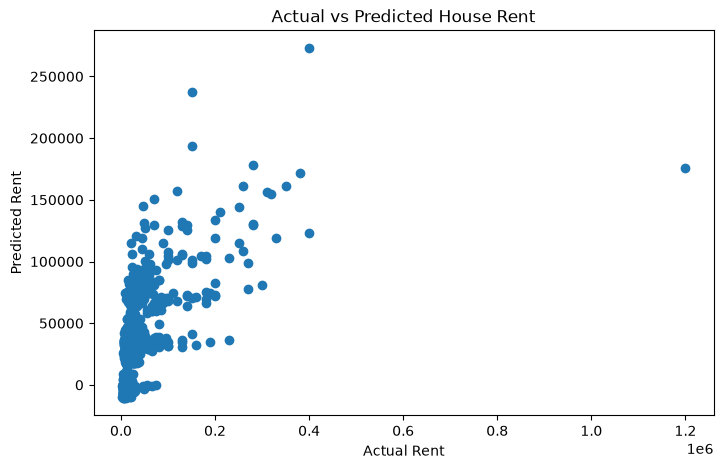

In [12]:
plt.figure(figsize=(8, 5))

plt.scatter(y_test, y_pred)

plt.xlabel("Actual Rent")
plt.ylabel("Predicted Rent")
plt.title("Actual vs Predicted House Rent")

plt.show()

In [13]:
result = pd.DataFrame({
    "Actual Rent": y_test.values,
    "Predicted Rent": y_pred
})

result["Difference"] = (
    result["Actual Rent"] -
    result["Predicted Rent"]
).abs()

display(result.head(10))

,Actual Rent,Predicted Rent,Difference
0,16000,38847.269247,22847.269247
1,12000,32531.087027,20531.087027
2,28000,26593.875741,1406.124259
3,8000,74624.277009,66624.277009
4,46000,145348.049524,99348.049524
5,17000,37794.572210,20794.572210
6,57000,28846.647399,28153.352601
7,9500,30425.692954,20925.692954
8,400000,123033.649210,276966.350790
9,15000,29372.995918,14372.995918
